# Qual é o melhor momento provável para uma nova compra?
## Segmentação comportamental por K-means e validação com Árvore de Decisão

**Problema:** a partir do histórico de compras de cada cliente, indicar **uma janela provável de recompra**, sem afirmar que ela oferece o menor preço de mercado. O K-means agrupa perfis por recência, frequência, valores e intervalos entre compras; a árvore de decisão serve de comparação.

**Base real:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), arquivo original (541.909 linhas × 8 colunas), transações de 01/12/2010 a 09/12/2011. Não se geram transações sintéticas. A variável-alvo `compra_em_30_dias` é **derivada das datas de compras reais**, não de respostas artificiais.

**Referências:**

1. CHEN, D.; SAIN, S. L.; GUO, K. (2012). *Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining*. Journal of Database Marketing & Customer Strategy Management, 19(3), 197–208. https://doi.org/10.1057/dbm.2012.17 — K-means, RFM e árvore de decisão aplicados à segmentação de clientes.
2. FADER, P. S.; HARDIE, B. G. S.; LEE, K. L. (2005). *“Counting Your Customers” the Easy Way: An Alternative to the Pareto/NBD Model*. Marketing Science, 24(2), 275–284. https://doi.org/10.1287/mksc.1040.0098 — previsão de recompra a partir do histórico de transações. **O modelo BG/NBD não será implementado**, por não integrar os algoritmos autorizados.

> **Limitação central:** conhecer quando alguém provavelmente voltará a comprar **não é o mesmo** que saber quando o preço ficará mínimo, nem significa que o produto anterior será novamente adquirido. Os resultados dependem de uma base histórica de uma varejista britânica de presentes, com clientela e períodos específicos.

### Fluxo de execução
1. Importar dados **reais** da UCI; 2. auditar e limpar; 3. descrever compras; 4. construir fotografias temporais das informações disponíveis em cada data; 5. gerar rótulos de compras futuras de 30 dias; 6. dividir cronologicamente; 7. ajustar K-means apenas com treino; 8. atribuir taxa de recompra a cada cluster usando **apenas o treino**; 9. comparar com Árvore de Decisão; 10. avaliar no teste intocado; 11. gerar gráficos, recomendações ilustrativas históricas e relatório preenchido.

## 0. Preparação e versões

Execute todas as células na ordem. Ambiente recomendado: Jupyter ou Google Colab com a base original fornecida na pasta; pacotes `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `openpyxl`, `python-docx`.

A base original **`online+retail.zip` já está incluída na entrega**; coloque o ZIP ao lado do notebook e execute tudo sem internet. Alternativamente, `Online Retail.xlsx` ou download UCI. O código nunca substitui o arquivo por uma base inventada.

In [1]:
from pathlib import Path
import io, zipfile, urllib.request, warnings, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from sklearn.tree import DecisionTreeClassifier
import sklearn

SEMENTE = 42
PASTA = Path('resultados_projeto')
PASTA.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5), 'font.size':10, 'figure.dpi':110})
print('Python:', sys.version.split()[0], '| pandas:',pd.__version__,
      '| scikit-learn:',sklearn.__version__)

Python: 3.13.5 | pandas: 2.2.3 | scikit-learn: 1.8.0


## 1. Download do conjunto de dados oficial

O endereço pertence à UCI (origem do dataset). A planilha é lida integralmente; não há seleção de linhas para produzir resultados. Em caso de indisponibilidade, o código informa como fornecer o arquivo original.

In [2]:
# A base pública original enviada pelo usuário está no ZIP ao lado do notebook.
# Prioridade: ZIP local, depois XLSX local, por último UCI oficial.
ARQUIVO_ZIP = Path('online+retail.zip')
ARQUIVO_XLSX = Path('Online Retail.xlsx')
URL_OFICIAL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
if ARQUIVO_ZIP.exists():
    print('Lendo o ZIP original completo enviado pelo usuário (sem amostragem).')
    with zipfile.ZipFile(ARQUIVO_ZIP) as z:
        candidatos=[nome for nome in z.namelist() if nome.lower().endswith('.xlsx')]
        if len(candidatos)!=1: raise ValueError('Esperada uma única planilha XLSX no ZIP original')
        with z.open(candidatos[0]) as arquivo:
            dados_brutos=pd.read_excel(io.BytesIO(arquivo.read()),engine='openpyxl')
elif ARQUIVO_XLSX.exists():
    print('Lendo a planilha original completa local (sem amostragem).')
    dados_brutos=pd.read_excel(ARQUIVO_XLSX,engine='openpyxl')
else:
    print('Baixando o dataset real da UCI...')
    try:
        with urllib.request.urlopen(URL_OFICIAL,timeout=120) as resp: zip_bytes=resp.read()
        with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
            candidatos=[nome for nome in z.namelist() if nome.lower().endswith('.xlsx')]
            if not candidatos: raise FileNotFoundError('ZIP da UCI sem planilha XLSX.')
            with z.open(candidatos[0]) as f: dados_brutos=pd.read_excel(io.BytesIO(f.read()),engine='openpyxl')
    except Exception as exc:
        raise RuntimeError('Forneça o arquivo original online+retail.zip ou Online Retail.xlsx ao lado do notebook: '+str(exc)) from exc

print('Dimensões brutas:',dados_brutos.shape)
assert len(dados_brutos)==541909, 'Arquivo diferente da versão original UCI de 2010–2011.'
assert set(['InvoiceNo','StockCode','Description','Quantity','InvoiceDate',
            'UnitPrice','CustomerID','Country']).issubset(dados_brutos.columns)
display(dados_brutos.head())

Lendo o ZIP original completo enviado pelo usuário (sem amostragem).


Dimensões brutas: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Auditoria exploratória: ausências, tipos e transações inválidas

Primeiro quantificamos todos os problemas na **base inteira**; só depois excluímos linhas sem identificação de cliente, cancelamentos e linhas que não representam vendas válidas. Não preenchemos IDs fictícios. Os outliers monetários são **reportados**, mas não são automaticamente excluídos porque compras atacadistas de grande volume podem ser legítimas.

TIPOS DE DADOS
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

NULOS POR COLUNA


,quantidade_ausente
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,quantidade
linhas_brutas,541909
colunas_brutas,8
customer_id_ausente,135080
descricao_ausente,1454
data_invalida_ou_ausente,0
quantidade_nao_positiva,10624
preco_nao_positivo,2517
linhas_com_cancelamento,9288
duplicatas_exatas,5268


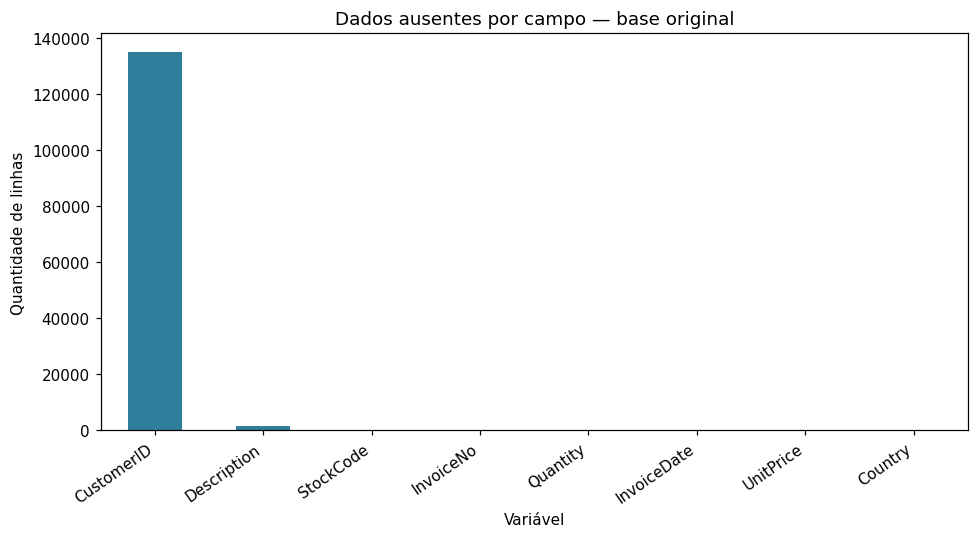

In [3]:
print('TIPOS DE DADOS')
print(dados_brutos.dtypes)
nulos = dados_brutos.isna().sum().sort_values(ascending=False)
print('\nNULOS POR COLUNA')
display(nulos.to_frame('quantidade_ausente'))

raw = dados_brutos.copy()
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
num_qtd_nao_positiva = int((raw['Quantity']<=0).sum())
num_preco_nao_positivo = int((raw['UnitPrice']<=0).sum())
num_cancelamento = int(raw['InvoiceNo'].astype(str).str.startswith('C').sum())
num_id_ausente = int(raw['CustomerID'].isna().sum())

check = pd.Series({
 'linhas_brutas':len(raw), 'colunas_brutas':raw.shape[1],
 'customer_id_ausente':num_id_ausente,
 'descricao_ausente':int(raw['Description'].isna().sum()),
 'data_invalida_ou_ausente':int(raw['InvoiceDate'].isna().sum()),
 'quantidade_nao_positiva':num_qtd_nao_positiva,
 'preco_nao_positivo':num_preco_nao_positivo,
 'linhas_com_cancelamento':num_cancelamento,
 'duplicatas_exatas':int(raw.duplicated().sum())
})
check.to_csv(PASTA/'auditoria_bruta.csv',header=['quantidade'])
display(check.to_frame('quantidade'))

ax=nulos.plot(kind='bar', color='#307e9c')
ax.set_title('Dados ausentes por campo — base original')
ax.set_ylabel('Quantidade de linhas'); ax.set_xlabel('Variável')
plt.xticks(rotation=35, ha='right');plt.tight_layout()
plt.savefig(PASTA/'01_valores_ausentes.png',dpi=180);plt.show()

In [4]:
valido = (raw['CustomerID'].notna() & raw['InvoiceDate'].notna()
          & raw['InvoiceNo'].notna() & (raw['Quantity']>0)
          & (raw['UnitPrice']>0)
          & ~raw['InvoiceNo'].astype(str).str.startswith('C'))
limpo = raw.loc[valido].drop_duplicates().copy()
limpo['CustomerID'] = limpo['CustomerID'].astype(int).astype(str)
limpo['receita_linha'] = limpo['Quantity'] * limpo['UnitPrice']
limpo['data'] = limpo['InvoiceDate'].dt.normalize()

print('Linhas após filtros:',len(limpo))
print('Clientes únicos:',limpo['CustomerID'].nunique())
print('Datas:',limpo['data'].min().date(),'até',limpo['data'].max().date())
q1,q3 = limpo['receita_linha'].quantile([0.25,0.75])
limite_outlier = q3+1.5*(q3-q1)
outliers = int((limpo['receita_linha']>limite_outlier).sum())
print('Valor-linha > Q3 + 1,5 IQR:',outliers,
      f'({outliers/len(limpo):.1%}). Não removidos.')

diagnostico = pd.Series({
    'linhas_brutas':len(raw),'linhas_validas':len(limpo),
    'linhas_excluidas':len(raw)-len(limpo),
    'clientes_identificados':limpo['CustomerID'].nunique(),
    'transacoes_unicas':limpo['InvoiceNo'].nunique(),
    'linhas_extremas_regra_iqr':outliers,
    'limite_iqr_em_gbp':float(limite_outlier)
})
diagnostico.to_csv(PASTA/'diagnostico_limpeza.csv',header=['valor'])
display(diagnostico.to_frame('valor'))
assert len(limpo)>0 and (limpo['receita_linha']>0).all()

Linhas após filtros: 392692
Clientes únicos: 4338
Datas: 2010-12-01 até 2011-12-09
Valor-linha > Q3 + 1,5 IQR: 31231 (8.0%). Não removidos.


,valor
linhas_brutas,541909.000
linhas_validas,392692.000
linhas_excluidas,149217.000
clientes_identificados,4338.000
transacoes_unicas,18532.000
linhas_extremas_regra_iqr,31231.000
limite_iqr_em_gbp,42.075


## 3. Visualizações reais: tempo e comportamento de compra

Os gráficos a seguir são feitos **exclusivamente a partir da base limpa**. Datas de transação pertencem à observação histórica da UCI, não ao calendário atual.

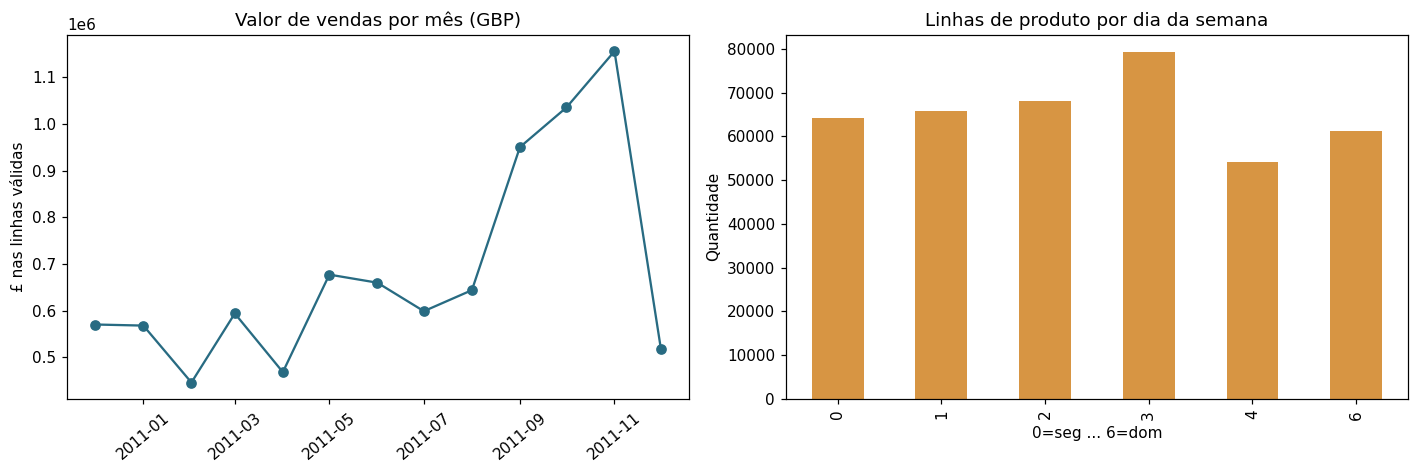

Dias de compra distintos: 16763
Clientes com >=2 dias de compra: 2790
Percentis dos intervalos:


,dias
0.25,12.0
0.50,28.0
0.75,58.0
0.90,110.0
0.95,155.0


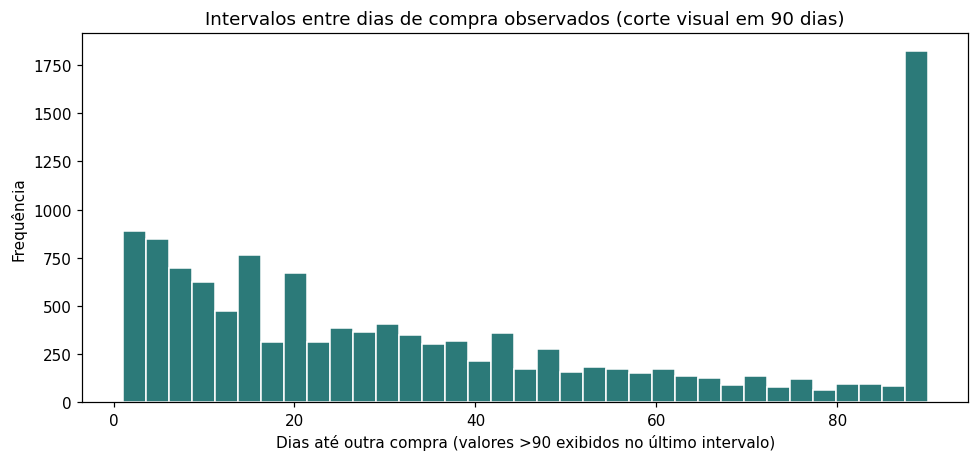

In [5]:
fat_mes = (limpo.assign(mes=limpo['data'].dt.to_period('M').dt.to_timestamp())
           .groupby('mes')['receita_linha'].sum())
fig,axs=plt.subplots(1,2,figsize=(13,4.4))
axs[0].plot(fat_mes.index,fat_mes.values,marker='o',color='#286b82')
axs[0].set(title='Valor de vendas por mês (GBP)',ylabel='£ nas linhas válidas')
axs[0].tick_params(axis='x',rotation=40)
limpo['InvoiceDate'].dt.dayofweek.value_counts().sort_index().plot.bar(ax=axs[1],color='#d79543')
axs[1].set(title='Linhas de produto por dia da semana',xlabel='0=seg ... 6=dom',ylabel='Quantidade')
plt.tight_layout();plt.savefig(PASTA/'02_compras_no_tempo.png',dpi=180);plt.show()

# Uma mesma fatura pode incluir centenas de produtos; para intervalo entre
# compras, a unidade correta é dia de compra por cliente, não linha de produto.
compras_dia=(limpo.groupby(['CustomerID','data'],as_index=False)
             .agg(valor_dia=('receita_linha','sum'),
                  itens_dia=('Quantity','sum'))
             .sort_values(['CustomerID','data']).reset_index(drop=True))
compras_dia['gap_dias']=compras_dia.groupby('CustomerID')['data'].diff().dt.days
intervalos = compras_dia['gap_dias'].dropna()
print('Dias de compra distintos:',len(compras_dia))
print('Clientes com >=2 dias de compra:',int(compras_dia.groupby('CustomerID').size().ge(2).sum()))
print('Percentis dos intervalos:')
display(intervalos.quantile([.25,.5,.75,.90,.95]).to_frame('dias'))
fig,ax=plt.subplots(figsize=(9,4.3))
ax.hist(intervalos.clip(upper=90),bins=35,color='#2c7a79',edgecolor='white')
ax.set(title='Intervalos entre dias de compra observados (corte visual em 90 dias)',
       xlabel='Dias até outra compra (valores >90 exibidos no último intervalo)',ylabel='Frequência')
plt.tight_layout();plt.savefig(PASTA/'03_intervalos_reais.png',dpi=180);plt.show()

## 4. Engenharia de atributos em fotografias temporais (sem vazamento)

A unidade de análise é o **cliente em uma data de referência** (`data_referencia`). Cada fotografia usa **somente** compras anteriores ao começo desse dia; o rótulo `compra_em_30_dias` é 1 se ocorrer uma compra nos **30 dias seguintes**; 0 caso contrário.

Características obtidas: recência (dias desde última compra), frequência total (dias de compra), valores acumulados e nos últimos 90 dias, tíquete médio, mediana e variabilidade de intervalos, proporção de compras aos fins de semana e tempo de relacionamento. Clientes com menos de **dois dias distintos** de compras não possuem um intervalo próprio confiável e são excluídos **desta análise específica**, sem inventar lacunas.

A divisão é **cronológica**, nunca aleatória: treinamento em 1/4–1/8/2011 (5 fotografias), validação 1/9/2011 e teste 1/10 e 1/11/2011. Os 30 dias subsequentes ao último teste terminam em 1/12/2011, dentro do período disponível.

In [6]:
ATRIBUTOS=['recencia_dias','dias_compra_total','gasto_total','ticket_medio',
           'dias_compra_90','gasto_90','intervalo_mediano','intervalo_desvio',
           'fracao_fim_semana','relacionamento_dias']
DATAS_REFERENCIA=pd.to_datetime(['2011-04-01','2011-05-01','2011-06-01',
 '2011-07-01','2011-08-01','2011-09-01','2011-10-01','2011-11-01'])

def gerar_fotografia(data_ref):
    """Histórico estritamente anterior ao cutoff; rótulo estritamente futuro."""
    passado=compras_dia.loc[compras_dia['data']<data_ref].copy()
    passado=passado.sort_values(['CustomerID','data'])
    g=passado.groupby('CustomerID')
    f=g.agg(primeira=('data','min'),ultima=('data','max'),
            dias_compra_total=('data','size'),
            gasto_total=('valor_dia','sum'),ticket_medio=('valor_dia','mean'))
    gaps=passado.assign(gap=passado.groupby('CustomerID')['data'].diff().dt.days)
    stats_gaps=(gaps.groupby('CustomerID')['gap']
                     .agg(intervalo_mediano='median',intervalo_desvio='std'))
    f=f.join(stats_gaps)
    f['recencia_dias']=(data_ref-f['ultima']).dt.days
    f['relacionamento_dias']=(data_ref-f['primeira']).dt.days
    ultimos90=passado.loc[passado['data']>=data_ref-pd.Timedelta(days=90)]
    f=f.join(ultimos90.groupby('CustomerID').agg(
        dias_compra_90=('data','size'),gasto_90=('valor_dia','sum')))
    f[['dias_compra_90','gasto_90']]=f[['dias_compra_90','gasto_90']].fillna(0)
    passado['fim_semana']=(passado['data'].dt.dayofweek>=5).astype(float)
    f['fracao_fim_semana']=passado.groupby('CustomerID')['fim_semana'].mean()
    f=f.loc[f['dias_compra_total']>=2].copy()
    proximos=compras_dia.loc[(compras_dia['data']>=data_ref)&
                         (compras_dia['data']<data_ref+pd.Timedelta(days=30)),'CustomerID'].unique()
    f['compra_em_30_dias']=f.index.isin(proximos).astype(int)
    f['data_referencia']=data_ref
    f['ultima_compra']=f['ultima']
    return f.reset_index()[['CustomerID','data_referencia','ultima_compra']+ATRIBUTOS+
                           ['compra_em_30_dias']]

fotos=[gerar_fotografia(t) for t in DATAS_REFERENCIA]
snapshots=pd.concat(fotos,ignore_index=True)
snapshots.to_csv(PASTA/'fotografias_temporais.csv',index=False)
print('Fotografias disponíveis:',len(snapshots))
print('Rótulos:',snapshots['compra_em_30_dias'].value_counts().to_dict())
assert snapshots.groupby('data_referencia')['compra_em_30_dias'].nunique().min()==2, 'Verifique classes nas datas.'
display(snapshots.groupby('data_referencia')['compra_em_30_dias']
         .agg(observacoes='size',proporcao_positiva='mean').round(3))

Fotografias disponíveis: 12926
Rótulos: {0: 7751, 1: 5175}


,observacoes,proporcao_positiva
data_referencia,,
2011-04-01,837,0.427
2011-05-01,1061,0.475
2011-06-01,1336,0.409
2011-07-01,1556,0.368
2011-08-01,1745,0.353
2011-09-01,1890,0.401
2011-10-01,2121,0.359
2011-11-01,2380,0.445


Treino: 6535 validação: 1890 teste: 4501
Proporção alvo positivo - treino, validação, teste: 0.397 0.401 0.405


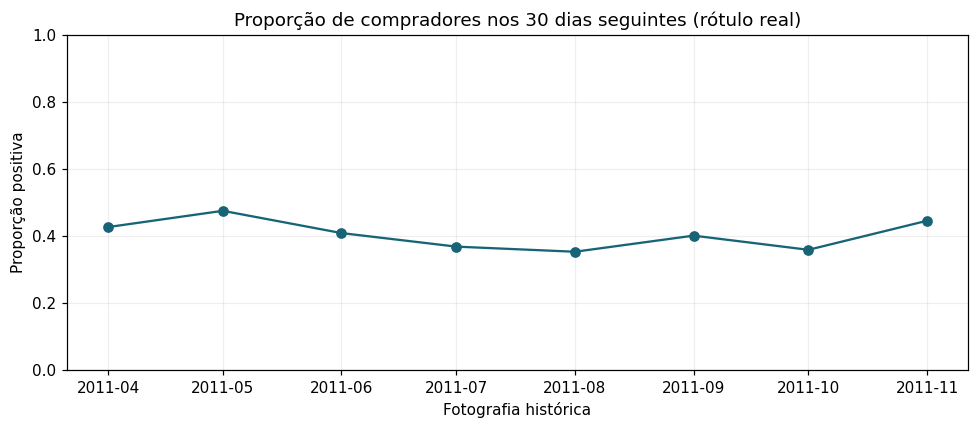

In [7]:
treino=snapshots.loc[snapshots.data_referencia<=pd.Timestamp('2011-08-01')].copy()
validacao=snapshots.loc[snapshots.data_referencia==pd.Timestamp('2011-09-01')].copy()
teste=snapshots.loc[snapshots.data_referencia>=pd.Timestamp('2011-10-01')].copy()
X_tr=treino[ATRIBUTOS]; y_tr=treino['compra_em_30_dias'].values
X_va=validacao[ATRIBUTOS]; y_va=validacao['compra_em_30_dias'].values
X_te=teste[ATRIBUTOS]; y_te=teste['compra_em_30_dias'].values
print('Treino:',len(treino),'validação:',len(validacao),'teste:',len(teste))
print('Proporção alvo positivo - treino, validação, teste:',
      *[round(x.mean(),3) for x in [y_tr,y_va,y_te]])
assert max(treino.data_referencia)<min(validacao.data_referencia)<min(teste.data_referencia)
fig,ax=plt.subplots(figsize=(9,4))
taxas=snapshots.groupby('data_referencia')['compra_em_30_dias'].agg(['mean','size'])
ax.plot(taxas.index,taxas['mean'],marker='o',color='#176477')
ax.set(title='Proporção de compradores nos 30 dias seguintes (rótulo real)',
       xlabel='Fotografia histórica',ylabel='Proporção positiva',ylim=(0,1))
ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(PASTA/'04_taxas_temporais.png',dpi=180);plt.show()

## 5. K-means: representação, escala e seleção de K

O K-means minimiza a soma das distâncias quadráticas aos centróides. **Todas** as transformações são ajustadas com `X_tr` apenas. Valores não negativos e assimétricos passam por `log1p`, mediana imputa eventuais faltas e `StandardScaler` iguala as escalas. Comparamos K entre 2 e 8 pelo método do cotovelo (inércia) e coeficiente de silhueta. A silhueta é calculada somente em amostra **real do treino** por eficiência; a escolha de K não utiliza os rótulos.

K escolhido pela maior silhueta no treino: 3


,k,inercia,silhueta
0,2,51022.429,0.211
1,3,42790.009,0.241
2,4,37800.885,0.210
3,5,34240.614,0.218
4,6,31364.388,0.203
5,7,29288.232,0.196
6,8,27559.163,0.197


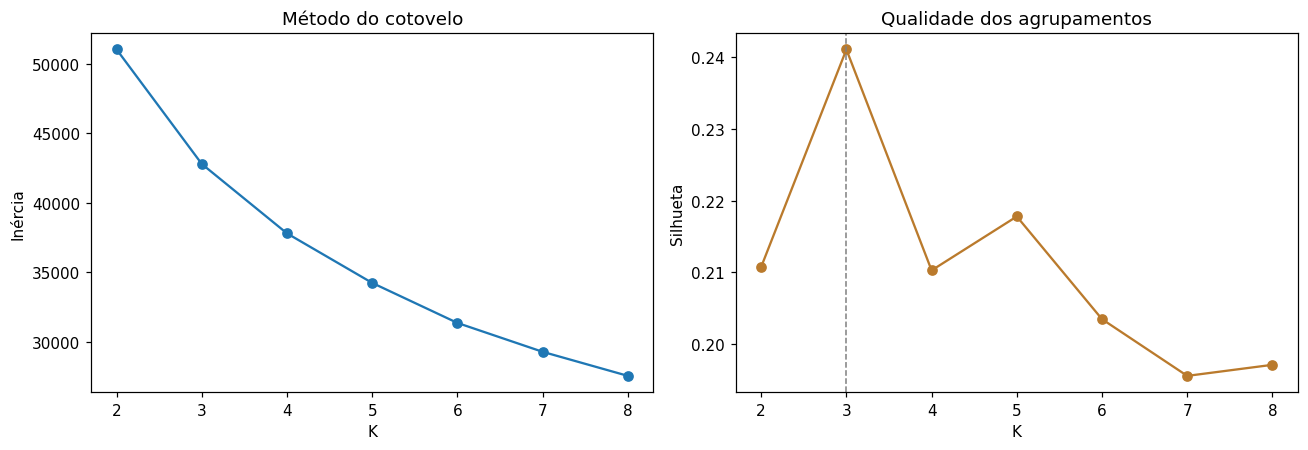

In [8]:
assert (X_tr[ATRIBUTOS].dropna()>=0).all().all()
# log1p não cria dados: apenas transforma a escala de atributos observados.
imp=SimpleImputer(strategy='median')
Z_tr=imp.fit_transform(np.log1p(X_tr))
scaler=StandardScaler()
Z_tr=scaler.fit_transform(Z_tr)

def transformar(X):
    return scaler.transform(imp.transform(np.log1p(X[ATRIBUTOS])))

Z_va=transformar(X_va); Z_te=transformar(X_te)
ks=list(range(2,min(8,len(X_tr)-1)+1))
linhas_k=[]
for k in ks:
    obj=KMeans(n_clusters=k,init='k-means++',n_init=15,random_state=SEMENTE)
    grupos=obj.fit_predict(Z_tr)
    sil=silhouette_score(Z_tr,grupos,sample_size=min(2500,len(Z_tr)),
                         random_state=SEMENTE)
    linhas_k.append({'k':k,'inercia':obj.inertia_,'silhueta':sil})
comparacao_k=pd.DataFrame(linhas_k)
melhor_k=int(comparacao_k.loc[comparacao_k['silhueta'].idxmax(),'k'])
print('K escolhido pela maior silhueta no treino:',melhor_k)
display(comparacao_k.round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
axs[0].plot(comparacao_k.k,comparacao_k.inercia,marker='o');axs[0].set(xlabel='K',ylabel='Inércia',title='Método do cotovelo')
axs[1].plot(comparacao_k.k,comparacao_k.silhueta,marker='o',color='#ba7a2c')
axs[1].axvline(melhor_k,color='gray',ls='--',lw=1)
axs[1].set(xlabel='K',ylabel='Silhueta',title='Qualidade dos agrupamentos')
plt.tight_layout();plt.savefig(PASTA/'05_escolha_k.png',dpi=180);plt.show()

## 6. Formação e interpretação dos clusters

Os nomes dos grupos são **descritivos**, estabelecidos só depois de examinar os perfis observados. O número atribuído ao cluster não tem interpretação ordinal.

,clientes_fotografia,recencia_mediana,compras_mediana,gasto_mediano_gbp,intervalo_mediano_dias,prob_compra30_treino
cluster,,,,,,
0,1620,13.0,6.0,2822.60,21.5,0.69
1,739,120.0,2.0,625.48,36.0,0.19
2,4176,31.0,2.0,766.02,53.5,0.32


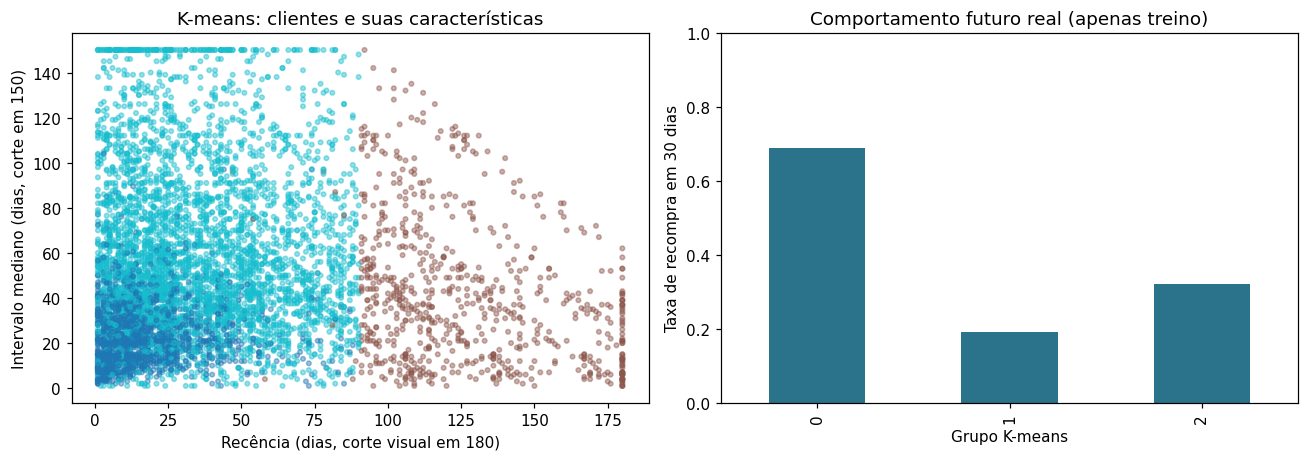

In [9]:
kmeans=KMeans(n_clusters=melhor_k,n_init=25,random_state=SEMENTE)
treino['cluster']=kmeans.fit_predict(Z_tr)
validacao['cluster']=kmeans.predict(Z_va)
teste['cluster']=kmeans.predict(Z_te)
perfil=treino.groupby('cluster').agg(
 clientes_fotografia=('CustomerID','size'),
 recencia_mediana=('recencia_dias','median'),
 compras_mediana=('dias_compra_total','median'),
 gasto_mediano_gbp=('gasto_total','median'),
 intervalo_mediano_dias=('intervalo_mediano','median'),
 prob_compra30_treino=('compra_em_30_dias','mean')).round(2)
perfil.to_csv(PASTA/'perfil_clusters.csv')
display(perfil)

fig,axs=plt.subplots(1,2,figsize=(12,4.3))
axs[0].scatter(treino['recencia_dias'].clip(upper=180),
               treino['intervalo_mediano'].clip(upper=150),
               c=treino['cluster'],cmap='tab10',s=9,alpha=.45)
axs[0].set(xlabel='Recência (dias, corte visual em 180)',
           ylabel='Intervalo mediano (dias, corte em 150)',title='K-means: clientes e suas características')
perfil['prob_compra30_treino'].plot.bar(ax=axs[1],color='#2a738a')
axs[1].set(xlabel='Grupo K-means',ylabel='Taxa de recompra em 30 dias',
           title='Comportamento futuro real (apenas treino)',ylim=(0,1))
plt.tight_layout();plt.savefig(PASTA/'06_perfis_clusters.png',dpi=180);plt.show()

## 7. K-means como sistema de recomendação de janela de 30 dias

**Como funciona a decisão:** agrupamos clientes pelo histórico (não supervisionado). Em seguida calculamos, **somente no treino**, qual fração de cada grupo comprou nos 30 dias subsequentes. Para um cliente novo, o centroide mais próximo determina o grupo e a respectiva taxa histórica. Essa taxa é **frequência empírica**, não probabilidade calibrada.

O limiar que transforma a taxa em recomendação binária é escolhido na validação; o teste fica intacto. O resultado responde: **“convém se planejar para uma compra nos próximos 30 dias, segundo o histórico deste perfil?”** Não responde: “será o dia mais barato?”.

In [10]:
taxa_por_cluster=treino.groupby('cluster')['compra_em_30_dias'].mean()
validacao['taxa_prevista_kmeans']=validacao['cluster'].map(taxa_por_cluster)
teste['taxa_prevista_kmeans']=teste['cluster'].map(taxa_por_cluster)
limiares=np.round(np.arange(0.10,0.91,0.05),2)
val_limiar=[]
for l in limiares:
    pv=(validacao['taxa_prevista_kmeans'].values>=l).astype(int)
    val_limiar.append({'limiar':l,'f1_val':f1_score(y_va,pv,zero_division=0),
                       'precision_val':precision_score(y_va,pv,zero_division=0),
                       'recall_val':recall_score(y_va,pv,zero_division=0)})
val_limiar=pd.DataFrame(val_limiar)
# Critério fixado antes do conjunto de teste: maior F1, desempate por Recall.
val_limiar=val_limiar.sort_values(['f1_val','recall_val','limiar'],ascending=[False,False,True])
limiar_otimo=float(val_limiar.iloc[0]['limiar'])
print('Limiar definido em validação:',limiar_otimo)
display(val_limiar.head(7).round(3))
pred_k=(teste['taxa_prevista_kmeans'].values>=limiar_otimo).astype(int)

Limiar definido em validação: 0.2


,limiar,f1_val,precision_val,recall_val
2,0.20,0.581,0.441,0.851
3,0.25,0.581,0.441,0.851
4,0.30,0.581,0.441,0.851
0,0.10,0.573,0.401,1.000
1,0.15,0.573,0.401,1.000
5,0.35,0.522,0.686,0.421
6,0.40,0.522,0.686,0.421


## 8. Segundo algoritmo: Árvore de Decisão (comparação)

Árvore de decisão é supervisionada: aprende cortes nos mesmos atributos de histórico para classificar se uma compra ocorrerá nos próximos 30 dias. Testamos profundidades e tamanhos mínimos de folhas; a seleção usa exclusivamente a validação. **Não acrescentamos modelos fora do escopo permitido**.

In [11]:
# A árvore recebe as mesmas transformações; as estatísticas de ajuste vêm só do treino.
hiperparametros=[]
melhor_arvore=None; melhor_f1=-1; melhor_combo=None
for profundidade in [3,5,7,10]:
    for folha in [15,35,70]:
        arv=DecisionTreeClassifier(max_depth=profundidade,min_samples_leaf=folha,
                                   class_weight='balanced',random_state=SEMENTE)
        arv.fit(Z_tr,y_tr)
        p=arv.predict(Z_va)
        score=f1_score(y_va,p,zero_division=0)
        hiperparametros.append({'max_depth':profundidade,'min_samples_leaf':folha,'F1_validacao':score})
        if score>melhor_f1:
            melhor_f1=score; melhor_arvore=arv; melhor_combo=(profundidade,folha)

print('Parâmetros selecionados na validação:',melhor_combo,'F1:',round(melhor_f1,3))
display(pd.DataFrame(hiperparametros).sort_values('F1_validacao',ascending=False).head())
pred_arvore=melhor_arvore.predict(Z_te)

Parâmetros selecionados na validação: (5, 35) F1: 0.608


,max_depth,min_samples_leaf,F1_validacao
4,5,35,0.607930
3,5,15,0.607076
6,7,15,0.591940
5,5,70,0.588235
1,3,35,0.579452


## 9. Avaliação final em dados cronologicamente posteriores

Métricas: `Precision`, `Recall`, `F1-score`, `Accuracy` e matrizes de confusão. `F1` considera o equilíbrio entre oportunidades acertadas e alertas desnecessários. O conjunto de teste **não influenciou** a escolha de K, do limiar nem da profundidade da árvore. A proporção de positivos é exibida para deixar explícito eventual desbalanceamento.

TESTE (datas de referência: out/nov 2011):


,Precision,Recall,F1-score,Accuracy
Modelo,,,,
K-means + taxa histórica por grupo,0.4561,0.8638,0.5970,0.5281
Árvore de Decisão,0.5631,0.6129,0.5869,0.6510
Regra majoritária (comparativo simples),0.0000,0.0000,0.0000,0.5954
Sempre recomendar recompra (comparativo simples),0.4046,1.0000,0.5761,0.4046


Fraçao positiva no teste: 0.405


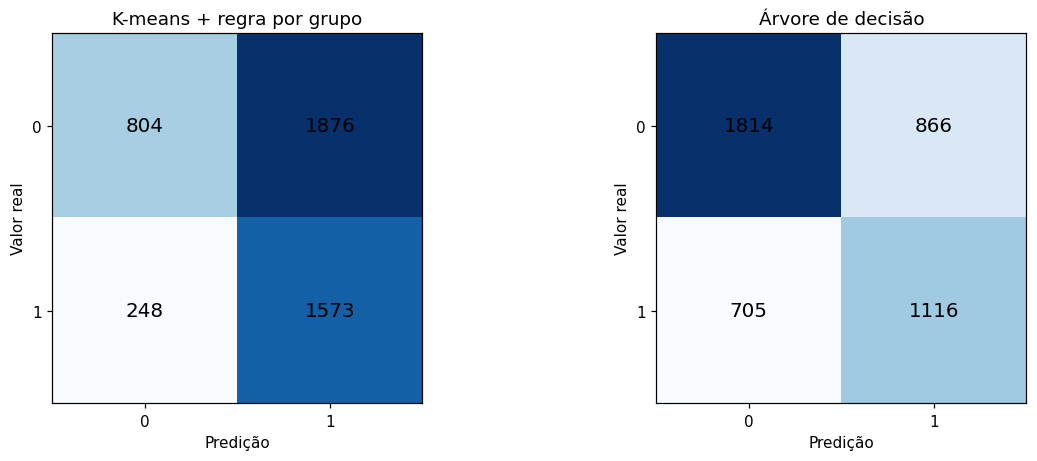

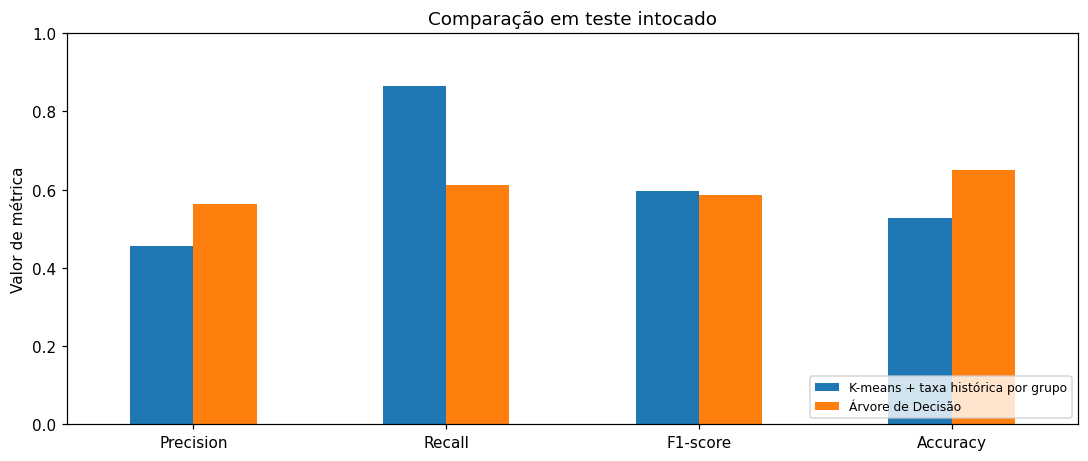

Matrizes de confusão [VN,FP; FN,VP]
K-means [[804, 1876], [248, 1573]]
Árvore [[1814, 866], [705, 1116]]


In [12]:
def medir(y,pred):
    return {'Precision':precision_score(y,pred,zero_division=0),
            'Recall':recall_score(y,pred,zero_division=0),
            'F1-score':f1_score(y,pred,zero_division=0),
            'Accuracy':accuracy_score(y,pred)}
metricas=pd.DataFrame({
    'K-means + taxa histórica por grupo':medir(y_te,pred_k),
    'Árvore de Decisão':medir(y_te,pred_arvore),
    'Regra majoritária (comparativo simples)':medir(y_te,np.repeat(int(y_tr.mean()>=.5),len(y_te))),
    'Sempre recomendar recompra (comparativo simples)':medir(y_te,np.ones(len(y_te),dtype=int))
}).T
metricas.index.name='Modelo'
metricas.to_csv(PASTA/'metricas_teste.csv',encoding='utf-8-sig')
print('TESTE (datas de referência: out/nov 2011):')
display(metricas.round(4))
print('Fraçao positiva no teste:',round(y_te.mean(),3))
fig,axs=plt.subplots(1,2,figsize=(11.5,4.3))
for a,p,title in zip(axs,[pred_k,pred_arvore],['K-means + regra por grupo','Árvore de decisão']):
    cm=confusion_matrix(y_te,p,labels=[0,1])
    a.imshow(cm,cmap='Blues')
    a.set(title=title,xlabel='Predição',ylabel='Valor real',
          xticks=[0,1],yticks=[0,1])
    for (i,j),v in np.ndenumerate(cm):a.text(j,i,str(v),ha='center',va='center',color='black',fontsize=13)
plt.tight_layout();plt.savefig(PASTA/'07_matrizes_confusao.png',dpi=180);plt.show()

ax=metricas.loc[['K-means + taxa histórica por grupo','Árvore de Decisão']].T.plot.bar(figsize=(10,4.3),rot=0)
ax.set(title='Comparação em teste intocado',ylabel='Valor de métrica',ylim=(0,1))
ax.legend(fontsize=8,loc='lower right');plt.tight_layout()
plt.savefig(PASTA/'08_metricas_comparadas.png',dpi=180);plt.show()

# Guardar cada decisão para auditoria reproduzível do teste, sem alterar modelo.
previsoes_teste=teste[['CustomerID','data_referencia','compra_em_30_dias','cluster','taxa_prevista_kmeans']].copy()
previsoes_teste['predicao_kmeans']=pred_k
previsoes_teste['predicao_arvore']=pred_arvore
previsoes_teste.to_csv(PASTA/'previsoes_individuais_teste.csv',index=False,encoding='utf-8-sig')
print('Matrizes de confusão [VN,FP; FN,VP]')
for modelo,p in [('K-means',pred_k),('Árvore',pred_arvore)]:
    print(modelo, confusion_matrix(y_te,p,labels=[0,1]).tolist())


## 9.1 Avaliação complementar: área ROC e estabilidade temporal

A curva ROC usa **escores** (taxa histórica por grupo para K-means e proporção de classe por folha para a Árvore). AUC descreve ordenação dos casos positivos; não significa probabilidade calibrada nem comprova o dia ideal. Também calculamos F1 separadamente para as duas datas de teste, para verificar se a média esconde oscilações.

,Modelo,ROC_AUC
0,K-means + taxa por grupo,0.6645
1,Árvore de Decisão,0.7002


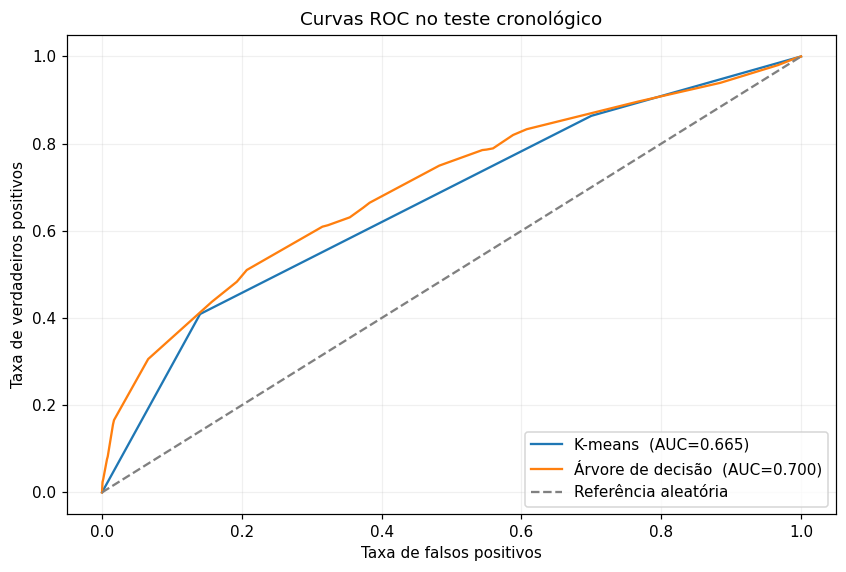

,data_referencia,modelo,n,taxa_real,Precision,Recall,F1-score,Accuracy
0,2011-10-01,K-means,2121,0.3588,0.4036,0.8607,0.5495,0.4936
1,2011-10-01,Árvore de Decisão,2121,0.3588,0.5027,0.6058,0.5495,0.6436
2,2011-11-01,K-means,2380,0.4454,0.5027,0.8660,0.6362,0.5588
3,2011-11-01,Árvore de Decisão,2380,0.4454,0.6150,0.6179,0.6165,0.6576


In [13]:
from sklearn.metrics import roc_curve, roc_auc_score

proba_arvore=melhor_arvore.predict_proba(Z_te)[:,1]
resultados_auc=pd.DataFrame({'Modelo':['K-means + taxa por grupo','Árvore de Decisão'],
 'ROC_AUC':[roc_auc_score(y_te,teste['taxa_prevista_kmeans']),roc_auc_score(y_te,proba_arvore)]})
resultados_auc.to_csv(PASTA/'auc_teste.csv',index=False)
display(resultados_auc.round(4))
fig,ax=plt.subplots(figsize=(7.8,5.3))
for titulo,scores in [('K-means',teste['taxa_prevista_kmeans']),('Árvore de decisão',proba_arvore)]:
    fpr,tpr,_=roc_curve(y_te,scores)
    ax.plot(fpr,tpr,label=f'{titulo}  (AUC={roc_auc_score(y_te,scores):.3f})')
ax.plot([0,1],[0,1],ls='--',color='gray',label='Referência aleatória')
ax.set(xlabel='Taxa de falsos positivos',ylabel='Taxa de verdadeiros positivos',title='Curvas ROC no teste cronológico')
ax.legend(loc='lower right');ax.grid(alpha=.18);plt.tight_layout()
plt.savefig(PASTA/'10_curvas_roc.png',dpi=180);plt.show()

linhas_mensais=[]
for data_ref,g in previsoes_teste.groupby('data_referencia'):
    for modelo,col in [('K-means','predicao_kmeans'),('Árvore de Decisão','predicao_arvore')]:
        res=medir(g['compra_em_30_dias'],g[col]);
        linhas_mensais.append({'data_referencia':data_ref.strftime('%Y-%m-%d'),'modelo':modelo,
                 'n':len(g),'taxa_real':g['compra_em_30_dias'].mean(),**res})
resultados_mensais=pd.DataFrame(linhas_mensais)
resultados_mensais.to_csv(PASTA/'metricas_por_mes_teste.csv',index=False)
display(resultados_mensais.round(4))

## 10. Importância dos atributos (modelo comparativo)

O K-means não fornece importância preditiva de atributos. A árvore permite examinar qual atributo mais contribuiu para suas divisões. Importância não representa causalidade nem garante melhoria nas compras.

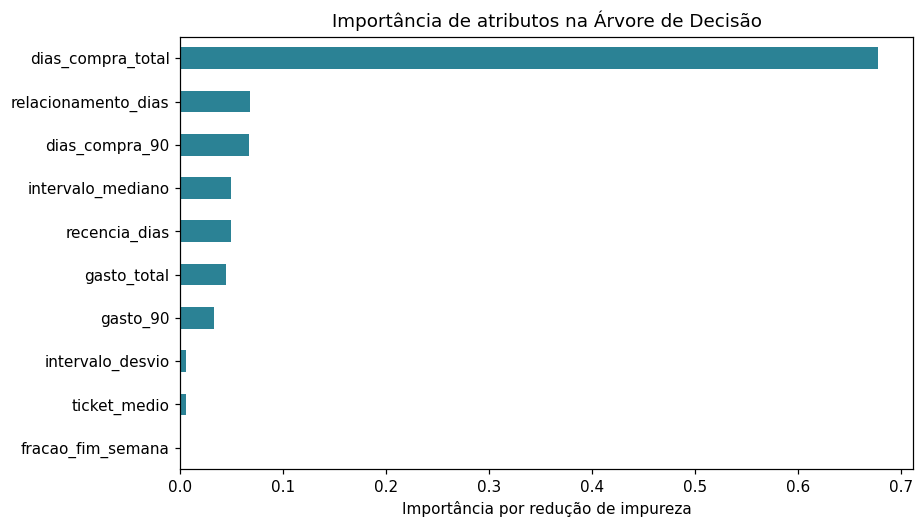

In [14]:
imp_arvore=pd.Series(melhor_arvore.feature_importances_,index=ATRIBUTOS).sort_values()
ax=imp_arvore.plot.barh(figsize=(8.5,4.9),color='#2b8295')
ax.set(title='Importância de atributos na Árvore de Decisão',xlabel='Importância por redução de impureza')
plt.tight_layout();plt.savefig(PASTA/'09_importancias_arvore.png',dpi=180);plt.show()

## 11. Exemplo de recomendação individual — apenas retrospectivo

Para demonstrar o uso prático, selecionamos clientes da fotografia histórica de **1º de novembro de 2011**. Um grupo com taxa acima do limiar recebe a indicação **“janela provável nos próximos 30 dias”**. Uma estimativa complementar do intervalo individual a partir da última compra é mostrada apenas quando disponível; se sua data estimada já passou, a informação indica atraso em relação à cadência histórica, e não uma data no futuro. A recomendação **não é de preço mínimo nem de um SKU específico**.

In [15]:
exemplo=teste.loc[teste.data_referencia==pd.Timestamp('2011-11-01')].copy()
exemplo['recomendacao_30d']=np.where(exemplo['taxa_prevista_kmeans']>=limiar_otimo,
 'Planejar possível compra nos próximos 30 dias','Sem sinal forte de compra nos próximos 30 dias')
exemplo['data_esperada_cadencia']=exemplo['ultima_compra']+pd.to_timedelta(
    exemplo['intervalo_mediano'],unit='D')
cols=['CustomerID','data_referencia','cluster','taxa_prevista_kmeans',
      'ultima_compra','intervalo_mediano','data_esperada_cadencia',
      'recomendacao_30d','compra_em_30_dias']
recomendacoes=exemplo[cols].sort_values('taxa_prevista_kmeans',ascending=False)
recomendacoes.to_csv(PASTA/'recomendacoes_retroativas.csv',index=False,encoding='utf-8-sig')
display(recomendacoes.head(12))
print('ATENÇÃO: demonstração histórica do conjunto de teste, não uma previsão para 2026.')

,CustomerID,data_referencia,cluster,taxa_prevista_kmeans,ultima_compra,intervalo_mediano,data_esperada_cadencia,recomendacao_30d,compra_em_30_dias
10554,12364,2011-11-01,0,0.691975,2011-10-30,36.0,2011-12-05 00:00:00,Planejar possível compra nos próximos 30 dias,0
12897,18219,2011-11-01,0,0.691975,2011-10-27,46.0,2011-12-12 00:00:00,Planejar possível compra nos próximos 30 dias,0
12899,18223,2011-11-01,0,0.691975,2011-10-31,31.0,2011-12-01 00:00:00,Planejar possível compra nos próximos 30 dias,0
12900,18225,2011-11-01,0,0.691975,2011-10-27,41.0,2011-12-07 00:00:00,Planejar possível compra nos próximos 30 dias,1
10581,12428,2011-11-01,0,0.691975,2011-08-11,19.0,2011-08-30 00:00:00,Planejar possível compra nos próximos 30 dias,1
10583,12431,2011-11-01,0,0.691975,2011-10-10,16.5,2011-10-26 12:00:00,Planejar possível compra nos próximos 30 dias,1
10585,12433,2011-11-01,0,0.691975,2011-10-27,48.0,2011-12-14 00:00:00,Planejar possível compra nos próximos 30 dias,1
10588,12437,2011-11-01,0,0.691975,2011-10-27,21.0,2011-11-17 00:00:00,Planejar possível compra nos próximos 30 dias,1
10575,12415,2011-11-01,0,0.691975,2011-10-05,27.0,2011-11-01 00:00:00,Planejar possível compra nos próximos 30 dias,1
10576,12417,2011-11-01,0,0.691975,2011-10-31,39.0,2011-12-09 00:00:00,Planejar possível compra nos próximos 30 dias,0


ATENÇÃO: demonstração histórica do conjunto de teste, não uma previsão para 2026.


## 12. Análise crítica: como interpretar a resposta

A resposta tecnicamente defensável é **condicional**: se os clusters distinguirem perfis reais, apresentarem taxas de recompra diferentes e a avaliação temporal do K-means for útil frente à regra majoritária, o agrupamento apoia recomendações sobre **quando esperar uma nova compra**. Se o classificador apresentar melhor desempenho, descrevemos essa limitação sem esconder o resultado.

A árvore pode superar o K-means por usar diretamente o rótulo de 30 dias, mas pode ser menos interpretável com muitas divisões. O K-means agrupa perfis e é útil para interpretação de cadências; isoladamente **não prevê o futuro**. Nem o K-means, nem a árvore comprovam oportunidade de menor preço, causalidade, compra por produto ou generalização para toda a população.

**Viés de seleção:** clientes sem ID, cancelamentos e clientes com apenas um dia de compra não entram no modelo. Um varejista de presentes e revenda atacadista pode gerar padrões sazonais diferentes de consumo recorrente cotidiano.

## 13. Gerador de relatório preenchido automaticamente com os resultados REAIS

Esta célula opcional cria o arquivo `resultados_projeto/Relatorio_Final_Com_Resultados.docx` com **métricas reais, tabelas e gráficos das células anteriores**. Assim não há necessidade de editar números manualmente nem de inventar valores. Para executar, instale `python-docx` se necessário.

In [16]:
try:
    from docx import Document
    from docx.shared import Cm,Pt,RGBColor
except ImportError as exc:
    raise ImportError('Instale a biblioteca com: pip install python-docx') from exc

doc=Document()
sec=doc.sections[0];sec.top_margin=Cm(3);sec.bottom_margin=Cm(2)
sec.left_margin=Cm(3);sec.right_margin=Cm(2)
normal=doc.styles['Normal'];normal.font.name='Times New Roman';normal.font.size=Pt(12)
normal.paragraph_format.line_spacing=1.5

def titulo(t):doc.add_heading(t,level=1)
def texto(t):doc.add_paragraph(t)
def tabela_dataframe(df,ndec=3):
    t=doc.add_table(rows=1,cols=len(df.columns)+1);t.style='Table Grid'
    for c,val in zip(t.rows[0].cells,['Modelo / grupo']+list(df.columns)):
        c.text=str(val)
    for idx,values in df.iterrows():
        row=t.add_row().cells; row[0].text=str(idx)
        for j,value in enumerate(values,1):
            row[j].text=f'{value:.{ndec}f}' if isinstance(value,(float,np.floating)) else str(value)

def figura(nome,legenda):
    p=PASTA/nome
    if p.exists():
        doc.add_picture(str(p),width=Cm(15.5))
        cp=doc.add_paragraph(legenda);cp.alignment=1

h=doc.add_paragraph('UNISATC — ENGENHARIA DA COMPUTAÇÃO');h.alignment=1
h=doc.add_paragraph('SEGMENTAÇÃO COM K-MEANS PARA IDENTIFICAR JANELAS PROVÁVEIS DE RECOMPRA');h.alignment=1
h=doc.add_paragraph('Relatório com resultados reproduzidos da base UCI Online Retail');h.alignment=1

titulo('1. INTRODUÇÃO, PROBLEMA E JUSTIFICATIVA')
texto('Compras em varejo eletrônico deixam registros de datas, valores e repetição de clientes. '
      'O problema é identificar, exclusivamente a partir de transações passadas, perfis com maior '
      'probabilidade empírica de voltar a comprar nos 30 dias seguintes. A tarefa não busca menor preço de mercado.')
texto('O K-means identifica padrões de comportamento; a árvore de decisão é comparação supervisionada. '
      'O alvo binário compra_em_30_dias é derivado das compras efetivamente observadas após cada fotografia histórica.')

titulo('2. OBJETIVOS')
texto('Objetivo geral: desenvolver e avaliar um método baseado em K-means que identifique perfis de recompra '
      'e recomende janelas prováveis de 30 dias, comparado com Árvore de Decisão.')
texto('Objetivos específicos: obter a base oficial; auditar ausências; limpar operações inválidas; '
      'agregar compras por cliente-dia; construir características e alvos temporais; ajustar clusters e limiares '
      'sem vazamento; comparar precisão, revocação, F1 e acurácia em período posterior.')

titulo('3. FUNDAMENTAÇÃO TEÓRICA')
texto('Chen, Sain e Guo (2012) mostram a utilidade da segmentação RFM por K-means e árvores de decisão para '
      'compreender consumidores em varejo eletrônico. Daí resulta a escolha de agrupar recência, frequência '
      'e valores, ampliados pela cadência de recompra. Fader, Hardie e Lee (2005) investigam recompra e '
      'projeções futuras a partir do histórico individual de transações, fundamentando o horizonte de nova '
      'compra. O seu modelo BG/NBD não é implementado neste projeto.')
texto('O K-means é não supervisionado e minimiza a soma das distâncias ao quadrado de cada observação ao '
      'centroide do cluster atribuído. A árvore de decisão é supervisionada e procura cortes nos atributos '
      'para distinguir a presença ou ausência da compra futura.')

titulo('4. METODOLOGIA E DESENVOLVIMENTO')
texto('Fonte: UCI Online Retail, 541.909 linhas originais e 8 colunas, registros de 2010-12-01 a 2011-12-09. '
      f'Foram retidas {len(limpo):,} linhas válidas correspondentes a {limpo.CustomerID.nunique():,} clientes. '
      f'Registros sem identificação de cliente na base original: {num_id_ausente:,}. '
      f'Linhas extremas pela regra Q3 + 1,5×IQR após limpeza: {outliers:,}; não removidas automaticamente.')
figura('01_valores_ausentes.png','Figura 1 — Valores ausentes nas variáveis originais. Fonte: elaboração própria, dados UCI.')
figura('02_compras_no_tempo.png','Figura 2 — Distribuição temporal de valores e transações. Fonte: elaboração própria, dados UCI.')
figura('03_intervalos_reais.png','Figura 3 — Intervalos observados entre compras de clientes. Fonte: elaboração própria, dados UCI.')
texto(f'Foram criadas {len(snapshots):,} fotografias de clientes em 8 datas mensais. Atributos principais: '
      'recência, dias de compra, gasto acumulado, tíquete, movimentação em 90 dias, intervalos, fração de '
      'compras ao fim de semana e relacionamento. Os alvos usam os 30 dias posteriores a cada fotografia.')
texto(f'Treino: {len(treino):,} linhas, abril–agosto de 2011. Validação: {len(validacao):,} linhas, setembro. '
      f'Teste: {len(teste):,} linhas, outubro–novembro. Valores monetários são expressos em libras esterlinas.')
texto('Tratamento: exclusão de linhas sem identificador, cancelamentos, quantidades e preços não positivos '
      'e duplicatas exatas. Não há codificação textual: variáveis nominais não entram no modelo; a '
      'identificação do cliente serve apenas para agrupar registros e não como preditor. '
      'Características não negativas foram transformadas por log1p, com mediana e StandardScaler '
      'ajustados somente no treino.')
texto(f'K-means: foram avaliados K=2 a K={max(ks)} por inércia e silhueta, selecionando K={melhor_k} '
      'sem utilização dos rótulos futuros. Para cada grupo, uma taxa de recompra histórica foi computada '
      f'no treino. O limiar de decisão foi determinado na validação: {limiar_otimo:.2f}. '
      f'Árvore: profundidade máxima={melhor_combo[0]}, folha mínima={melhor_combo[1]}, '
      'definidas na validação.')
figura('05_escolha_k.png','Figura 4 — Critérios de escolha do número de clusters. Fonte: elaboração própria, treino.')
figura('06_perfis_clusters.png','Figura 5 — Distribuição e taxas históricas dos grupos. Fonte: elaboração própria, treino.')

titulo('5. AVALIAÇÃO E ANÁLISE DE RESULTADOS')
texto(f'Conjunto de teste cronologicamente posterior, com taxa positiva de {y_te.mean():.1%}. '
      'Os hiperparâmetros foram definidos antes da avaliação final. A tabela apresenta resultados '
      'quantitativos calculados sem usar o teste no ajuste.')
tabela_dataframe(metricas.round(4),4)
figura('07_matrizes_confusao.png','Figura 6 — Matrizes de confusão para a compra nos 30 dias seguintes. Fonte: elaboração própria, teste.')
figura('08_metricas_comparadas.png','Figura 7 — Desempenho em teste intocado. Fonte: elaboração própria, teste.')
figura('09_importancias_arvore.png','Figura 8 — Importância dos atributos da árvore. Fonte: elaboração própria.')
figura('10_curvas_roc.png','Figura 9 — Curvas ROC no conjunto de teste. Fonte: elaboração própria.')
texto('AUC ROC no teste: K-means '+f'{resultados_auc.iloc[0].ROC_AUC:.3f}'+
     '; Árvore de Decisão '+f'{resultados_auc.iloc[1].ROC_AUC:.3f}'+'. AUC compara ranking de escores, não acurácia ou calibração. ' +
     'Foram avaliadas também as duas datas de teste separadamente; consultar metricas_por_mes_teste.csv.')
campeao=metricas.loc[['K-means + taxa histórica por grupo','Árvore de Decisão'],'F1-score'].idxmax()
texto(f'O maior F1 entre os dois modelos foi obtido por: {campeao}. '
      'Uma árvore com melhor F1 indica que a segmentação, por si só, pode não capturar toda a relação '
      'preditiva; o K-means continua útil para interpretação dos perfis. A comparação não indica '
      'causalidade nem identificação de preços mínimos.')

titulo('6. CONCLUSÃO E LIMITAÇÕES')
texto('Os resultados são específicos de uma base histórica e de uma avaliação retrospectiva. '
      'O objetivo alcançável é indicar probabilidade relativa de recompra em 30 dias, nunca a '
      'melhor oferta de preço ou a compra certa de um item determinado. Clientes anônimos ou com '
      'um único dia de compra não são cobertos, e padrões atuais exigiriam atualização de dados.')

titulo('7. REFERÊNCIAS')
texto('CHEN, D.; SAIN, S. L.; GUO, K. Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. Journal of Database Marketing & Customer Strategy Management, v. 19, n. 3, p. 197–208, 2012. DOI: https://doi.org/10.1057/dbm.2012.17.')
texto('FADER, P. S.; HARDIE, B. G. S.; LEE, K. L. “Counting Your Customers” the Easy Way: An Alternative to the Pareto/NBD Model. Marketing Science, v. 24, n. 2, p. 275–284, 2005. DOI: https://doi.org/10.1287/mksc.1040.0098.')
texto('UCI MACHINE LEARNING REPOSITORY. Online Retail. 2015. Disponível em: https://archive.ics.uci.edu/dataset/352/online+retail. Acesso em: 18 nov. 2026.')

destino=PASTA/'Relatorio_Final_Com_Resultados.docx'
doc.save(destino)
print('RELATÓRIO GERADO:',destino.resolve())

RELATÓRIO GERADO: /mnt/data/_exec_workspace/resultados_projeto/Relatorio_Final_Com_Resultados.docx
